In [1]:
import pandas as pd
import os
parent_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled/'
metric_dirs = os.listdir(parent_dir)
tcell_files = sorted([os.path.join(parent_dir,x,'tcell_contamination_metrics_layers_pooled.csv') for x in metric_dirs if os.path.exists(os.path.join(parent_dir,x,'tcell_contamination_metrics_layers_pooled.csv'))])
tcell_df = pd.concat([pd.read_csv(f) for f in tcell_files]).reset_index(drop=True)
# sep_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled/B10_B10/cell_type_separation_metrics_worstadj.csv')
# sep_df['tissue'].iloc[0]
tcell_df['dropout']= tcell_df['tissue'].apply(lambda x: x.split('_')[-1])

tcell_df['input_layer'].unique()

/tmp/ipykernel_1348261/2448146145.py:6: DtypeWarning: Columns (23,27) have mixed types. Specify dtype option on import or set low_memory=False.
  tcell_df = pd.concat([pd.read_csv(f) for f in tcell_files]).reset_index(drop=True)
/tmp/ipykernel_1348261/2448146145.py:6: DtypeWarning: Columns (23,27) have mixed types. Specify dtype option on import or set low_memory=False.
  tcell_df = pd.concat([pd.read_csv(f) for f in tcell_files]).reset_index(drop=True)
/tmp/ipykernel_1348261/2448146145.py:6: DtypeWarning: Columns (23,27) have mixed types. Specify dtype option on import or set low_memory=False.
  tcell_df = pd.concat([pd.read_csv(f) for f in tcell_files]).reset_index(drop=True)
/tmp/ipykernel_1348261/2448146145.py:6: DtypeWarning: Columns (23,27) have mixed types. Specify dtype option on import or set low_memory=False.
  tcell_df = pd.concat([pd.read_csv(f) for f in tcell_files]).reset_index(drop=True)
/tmp/ipykernel_1348261/2448146145.py:6: DtypeWarning: Columns (23,27) have mixed typ

array(['X', 'trial_0', 'trial_1', 'trial_2'], dtype=object)

In [2]:
tcell_df

,sample,target_cell_type_i,contaminating_cell_type_j,n_target_cells_total,n_proximal_to_j,n_distal_to_j,n_fit_cells,top_n,marker_overlap_n,marker_overlap_frac,...,group_achieved_removed_fractions,error,input_layer,evaluation_method,probability_layer,counts_layer,sample_replicate,dropout_label,dropout_fraction,dropout
0,st,malignant cell,smooth muscle cell,30217.0,6159.0,24058.0,30217.0,20.0,6.0,0.30,...,NaN,NaN,X,baseline,NaN,X,B10_B10,0pct,0.00,15pct
1,st,malignant cell,pericyte,30217.0,1091.0,29126.0,30217.0,20.0,5.0,0.25,...,NaN,NaN,X,baseline,NaN,X,B10_B10,0pct,0.00,15pct
2,st,malignant cell,macrophage,30217.0,2372.0,27845.0,30217.0,20.0,7.0,0.35,...,NaN,NaN,X,baseline,NaN,X,B10_B10,0pct,0.00,15pct
3,st,malignant cell,capillary endothelial cell,30217.0,3404.0,26813.0,30217.0,20.0,8.0,0.40,...,NaN,NaN,X,baseline,NaN,X,B10_B10,0pct,0.00,15pct
4,st,malignant cell,fibroblast of lung,30217.0,4112.0,26105.0,30217.0,20.0,6.0,0.30,...,NaN,NaN,X,baseline,NaN,X,B10_B10,0pct,0.00,15pct
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
436647,st,"CD4-positive, alpha-beta memory T cell",pericyte,3481.0,261.0,3220.0,3481.0,20.0,0.0,0.00,...,NaN,NaN,trial_2,split,NaN,split_purified_counts_trial_2,B9_B9,5pct,0.05,5pct
436648,st,"CD4-positive, alpha-beta memory T cell",plasmacytoid dendritic cell,3481.0,1288.0,2193.0,3481.0,20.0,0.0,0.00,...,NaN,NaN,trial_2,split,NaN,split_purified_counts_trial_2,B9_B9,5pct,0.05,5pct
436649,st,"CD4-positive, alpha-beta memory T cell",fibroblast of lung,3481.0,739.0,2742.0,3481.0,20.0,1.0,0.05,...,NaN,NaN,trial_2,split,NaN,split_purified_counts_trial_2,B9_B9,5pct,0.05,5pct
436650,st,"CD4-positive, alpha-beta memory T cell",capillary endothelial cell,3481.0,685.0,2796.0,3481.0,20.0,2.0,0.10,...,NaN,NaN,trial_2,split,NaN,split_purified_counts_trial_2,B9_B9,5pct,0.05,5pct


Text(0.5, 0.98, 'Strength of T-Cell Contamination vs Transcript dropout')

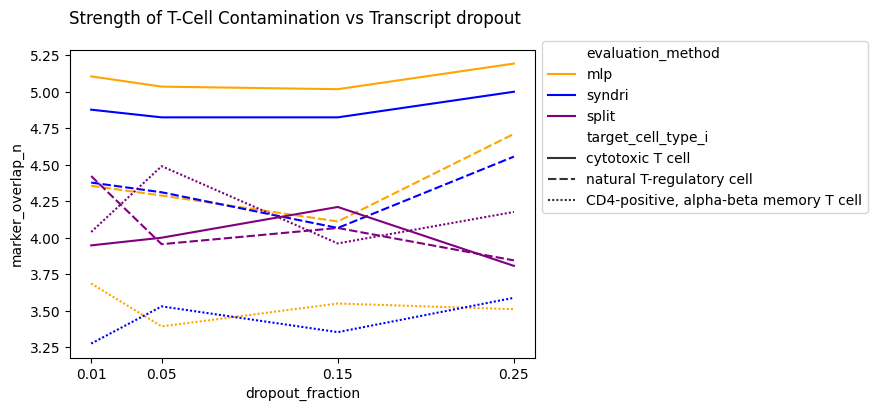

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
mal_df = tcell_df[(tcell_df['target_cell_type_i'].str.contains('T')) & 
                  (tcell_df['contaminating_cell_type_j'].str.contains('malignant'))&
                  # (tcell_df['dropout_fractiojn'])
                  (~tcell_df['target_removed_fraction'].isin([0.01,
                                                              0.02,
                                                              0.05,
                                                              0.1,
                                                            #   0.2,
                                                              ]))].reset_index(drop=True)
                  # (tcell_df['sample_replicate'].str.contains('_B1_'))].reset_index(drop=True)

fig,ax= plt.subplots(figsize=(6,4))
custom_colors = {
    'syndri': 'blue',  # Hex code
    'mlp': 'orange',     # Named color
    'split': 'purple'    # Shorthand notation
}
sns.lineplot(data=mal_df,x='dropout_fraction',y='marker_overlap_n',hue='evaluation_method',style='target_cell_type_i',ax=ax,errorbar=None,palette=custom_colors,hue_order=['mlp','syndri','split'])
ax.legend(bbox_to_anchor=(1,1.05))
ax.set_xticks([0.01,0.05,0.15,0.25])
fig.suptitle('Strength of T-Cell Contamination vs Transcript dropout')

In [4]:
mal_df.columns

Index(['sample', 'target_cell_type_i', 'contaminating_cell_type_j',
       'n_target_cells_total', 'n_proximal_to_j', 'n_distal_to_j',
       'n_fit_cells', 'top_n', 'marker_overlap_n', 'marker_overlap_frac',
       'overlap_genes', 'top_coef_genes', 'contaminating_type_markers',
       'zscore_mode', 'condition', 'tissue', 'source_file',
       'target_removed_fraction', 'admix_prob_threshold',
       'achieved_removed_fraction', 'cleaning_mode', 'probability_transform',
       'probability_removal_scale', 'cell_type_specific_removal',
       'group_admix_prob_thresholds', 'group_probability_removal_scales',
       'group_achieved_removed_fractions', 'error', 'input_layer',
       'evaluation_method', 'probability_layer', 'counts_layer',
       'sample_replicate', 'dropout_label', 'dropout_fraction', 'dropout'],
      dtype='object')

In [5]:
import ast
import itertools
from collections import Counter

import pandas as pd

filtered_df = mal_df.loc[
    mal_df["dropout_fraction"].eq(0.01)
].copy()

records = []

for method, method_df in filtered_df.groupby("evaluation_method"):
    for cell_type, ct_df in method_df.groupby("target_cell_type_i"):

        gene_lists = (
            ct_df["overlap_genes"]
            .dropna()
            .map(
                lambda x: ast.literal_eval(x)
                if isinstance(x, str)
                else x
            )
        )

        gene_counts = Counter(
            itertools.chain.from_iterable(gene_lists)
        )

        records.extend(
            {
                "evaluation_method": method,
                "cell_type": cell_type,
                "gene": gene,
                "count": count,
            }
            for gene, count in gene_counts.items()
        )

marker_counts = pd.DataFrame.from_records(
    records,
    columns=[
        "evaluation_method",
        "cell_type",
        "gene",
        "count",
    ],
)

marker_counts = marker_counts.sort_values(
    ["evaluation_method", "cell_type", "count"],
    ascending=[True, True, False],
).reset_index(drop=True)

In [6]:
import anndata as ad
st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/split_spatial_chromium/split_xenium/GSM9509167_breast_breast_B8_B8_rctd.h5ad')


In [7]:
ensembl_map=dict(zip(st_data.var.index,st_data.var['feature_name']))

In [8]:
marker_counts['gene_name']=marker_counts['gene'].map(ensembl_map)

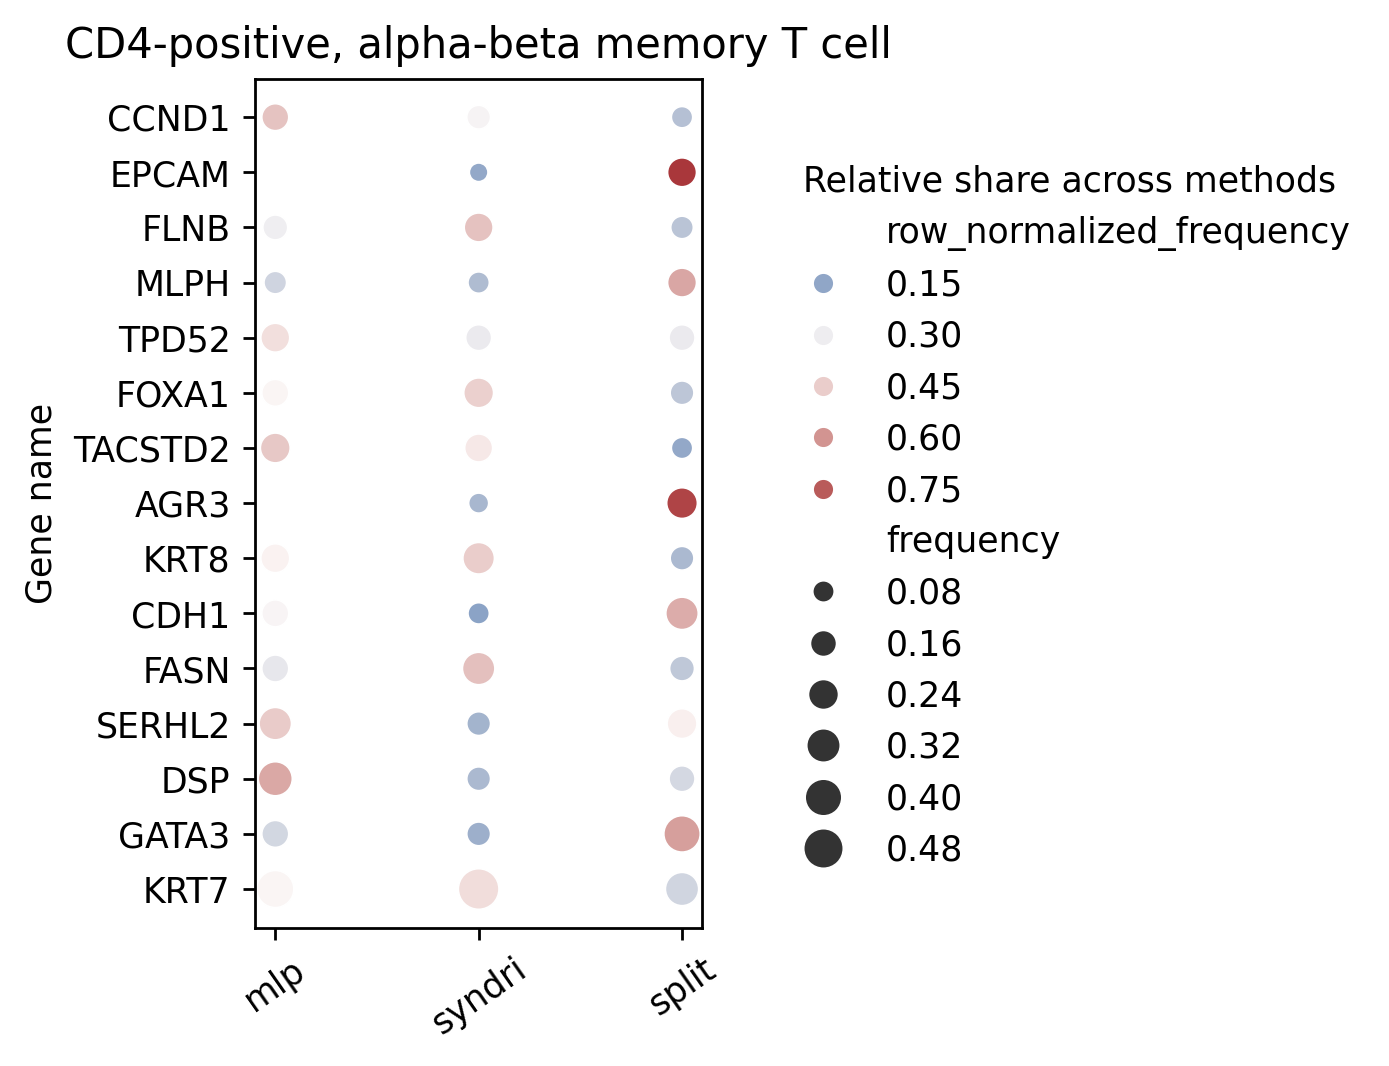

In [13]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
mal_df['evaluation_method']=pd.Categorical(mal_df['evaluation_method'],categories=['mlp','syndri','split'],ordered=True)
# Same subset used to construct marker_counts
filtered_df = mal_df.loc[
    mal_df["dropout_fraction"].eq(0.01)
].copy()

# Number of evaluations contributing to each method–cell-type group
evaluation_totals = (
    filtered_df
    .groupby(
        ["evaluation_method", "target_cell_type_i"],
        observed=True,
    )
    .size()
    .rename("n_evaluations")
    .reset_index()
    .rename(columns={"target_cell_type_i": "cell_type"})
)

# Convert counts into detection frequencies
plot_df = marker_counts.merge(
    evaluation_totals,
    on=["evaluation_method", "cell_type"],
    how="left",
)

plot_df["frequency"] = (
    plot_df["count"] / plot_df["n_evaluations"]
)

# Keep only the most informative genes within each cell type
n_genes = 20

gene_scores = (
    plot_df
    .groupby(
        ["cell_type", "gene_name"],
        observed=True,
    )["frequency"]
    .max()
    .reset_index()
)

top_genes = (
    gene_scores
    .sort_values(
        ["cell_type", "frequency"],
        ascending=[True, False],
    )
    .groupby("cell_type", observed=True)
    .head(n_genes)[["cell_type", "gene_name"]]
)

plot_df = plot_df.merge(
    top_genes,
    on=["cell_type", "gene_name"],
    how="inner",
)
method_order = ["mlp", "syndri", "split"]

plot_df["evaluation_method"] = pd.Categorical(
    plot_df["evaluation_method"],
    categories=method_order,
    ordered=True,
)

method_labels = {
    "mlp": "MLP",
    "syndri": "Syndri",
    "split": "SPLIT",
}

plot_df["method_label"] = (
    plot_df["evaluation_method"]
    .astype(str)
    .map(method_labels)
)

method_label_order = ["MLP", "Syndri", "SPLIT"]

plot_df = plot_df.sort_values("evaluation_method")
plot_df["row_normalized_frequency"] = (
    plot_df["frequency"]
    / plot_df.groupby(
        ["cell_type", "gene_name"],
        observed=True,
    )["frequency"].transform("sum")
)
n_genes_per_method = 8

top_by_method = (
    plot_df
    .sort_values(
        [
            "cell_type",
            "evaluation_method",
            "frequency",
        ],
        ascending=[True, True, False],
    )
    .groupby(
        ["cell_type", "evaluation_method"],
        observed=True,
    )
    .head(n_genes_per_method)
)

# Union of the top genes from all methods within each cell type
selected_genes = (
    top_by_method[
        ["cell_type", "gene_name"]
    ]
    .drop_duplicates()
)

plot_df = plot_df.merge(
    selected_genes,
    on=["cell_type", "gene_name"],
    how="inner",
)

# Optional explicit ordering
method_order = plot_df["evaluation_method"].drop_duplicates().tolist()
cell_types = plot_df["cell_type"].drop_duplicates().tolist()[:1]

ncols = 1
nrows = math.ceil(len(cell_types) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(3.5 * ncols, 4.5 * nrows),
    squeeze=False,
    dpi=250
)

axes = axes.ravel()

for i, (ax, cell_type) in enumerate(zip(axes, cell_types)):
    ct_df = plot_df.loc[
        plot_df["cell_type"].eq(cell_type)
    ].copy()

    gene_order = (
        ct_df
        .groupby("gene_name", observed=True)["frequency"]
        .max()
        .sort_values(ascending=True)
        .index
        .tolist()
    )

    ct_df["gene_name"] = pd.Categorical(
        ct_df["gene_name"],
        categories=gene_order,
        ordered=True,
    )

    from matplotlib.colors import TwoSlopeNorm

    share_norm = TwoSlopeNorm(
        vmin=0,
        vcenter=1 / 3,
        vmax=plot_df["row_normalized_frequency"].max(),
    )

    sns.scatterplot(
        data=ct_df,
        x="evaluation_method",
        y="gene_name",
        hue="row_normalized_frequency",
        size="frequency",
        hue_norm=share_norm,
        size_norm=(0, 1),
        sizes=(20, 250),
        palette="vlag",
        legend=(i == 0),
        ax=ax,
    )
    ax.set_title(cell_type)
    ax.set_xlabel("")
    ax.set_ylabel("Gene name" if i % ncols == 0 else "")
    ax.tick_params(axis="x", rotation=35)

# Retrieve the legend created on the first subplot
handles, labels = axes[0].get_legend_handles_labels()

# Remove subplot-level legends
for ax in axes[:len(cell_types)]:
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

# Remove unused panels
for ax in axes[len(cell_types):]:
    ax.remove()

# fig.suptitle(
#     "Recurring overlap genes by evaluation method and cell type",
#     y=0.99,
# )

# Shared figure-level legend
fig.legend(
    handles,
    labels,
    title="Relative share across methods",
    loc="center left",
    bbox_to_anchor=(0.88, 0.5),
    frameon=False,
)

# Reserve the right side for the legend
plt.tight_layout(
    rect=[0, 0, 0.87, 0.97]
)

plt.show()

<Axes: xlabel='n_distal_to_j', ylabel='n_proximal_to_j'>

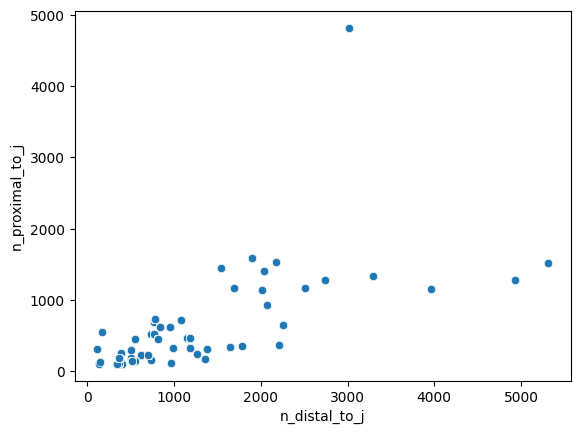

In [28]:
sns.scatterplot(data=mal_df, x='n_distal_to_j',y='n_proximal_to_j')

In [29]:
import pandas as pd
import os
parent_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled/'
metric_dirs = os.listdir(parent_dir)
tcell_files = sorted([os.path.join(parent_dir,x,'tcell_cosine_similarity_layers_pooled.csv') for x in metric_dirs if os.path.exists(os.path.join(parent_dir,x,'tcell_cosine_similarity_layers_pooled.csv'))])
tcell_df = pd.concat([pd.read_csv(f) for f in tcell_files]).reset_index(drop=True)
# tcell_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled/B13_B13/tcell_cosine_similarity_layers_pooled.csv')
# sep_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled/B10_B10/cell_type_separation_metrics_worstadj.csv')
# sep_df['tissue'].iloc[0]
# tcell_df['dropout']= tcell_df['tissue'].apply(lambda x: x.split('_')[-1])

# tcell_df['input_layer'].unique()

In [30]:
tcell_df['counts_layer'].unique()
# tcell_df[tcell_df['condition']=='uncorrected']['counts_layer'].unique()
# tcell_df['reference_cell_type'].unique()

array(['X', 'split_purified_counts_X', 'trial_0',
       'split_purified_counts_trial_0', 'trial_1',
       'split_purified_counts_trial_1', 'trial_2',
       'split_purified_counts_trial_2'], dtype=object)

Text(0.5, 0.98, 'T-Cell Cosine Similarity')

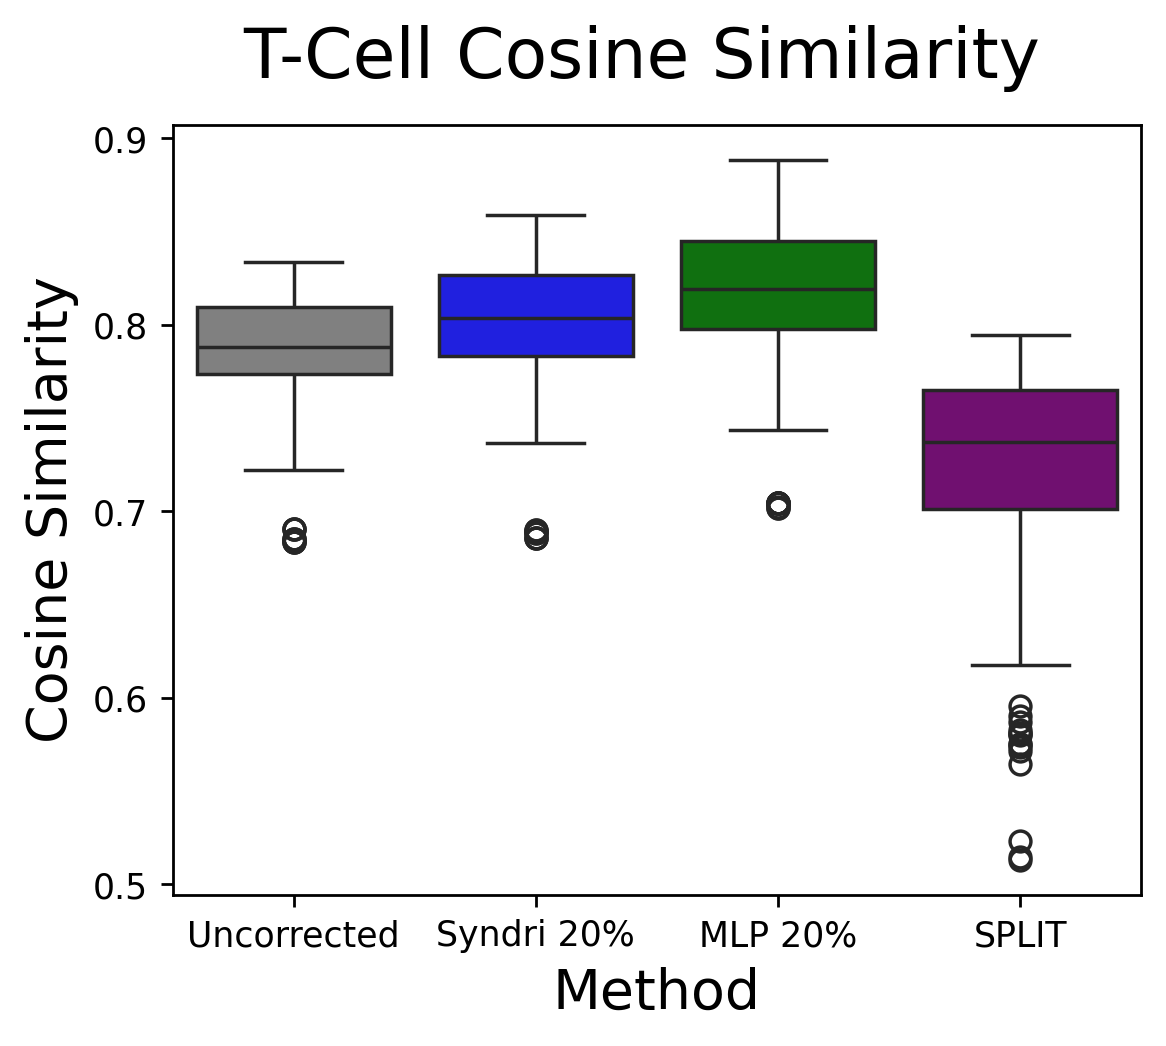

In [31]:
tcell_df

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plot_df = tcell_df.copy()

conditions=[
    'uncorrected',
    'syndri_cleaned_removed_frac_0.2',
    'mlp_cleaned_removed_frac_0.2',
    'split',
]

condition_labels={
    'uncorrected':'Uncorrected',
    'syndri_cleaned_removed_frac_0.2':'Syndri 20%',
    'mlp_cleaned_removed_frac_0.2':"MLP 20%",
    'split':'SPLIT',
}

colors = ['gray','blue','green','purple']


plot_df = plot_df[(plot_df['condition'].isin(conditions))&
                  (plot_df['dropout_fraction']==0.01)]
                #   (plot_df['reference_cell_type']=='cytotoxic')]
plot_df['condition_label'] = plot_df['condition'].map(condition_labels)
fig,ax= plt.subplots(figsize=(5,4),dpi=250)
ax=sns.boxplot(data=plot_df, x='condition_label',y='cosine_similarity',hue='condition_label',palette=colors,ax=ax)
# ax=sns.stripplot(data=plot_df, x='dropout_fraction',y='cosine_similarity',hue='condition_label',color='black',alpha=0.5,ax=ax,dodge=True)
# ax=sns.lineplot(data=plot_df, x='dropout_fraction',y='cosine_similarity',hue='condition_label',style='reference_cell_type',palette='tab10',ax=ax)

# ax.legend(bbox_to_anchor=(1.0,0.95))
ax.set_xlabel('Method',fontsize=16)
ax.set_ylabel('Cosine Similarity',fontsize=16)
ax.set_yticks(np.arange(0.5,0.91,0.1))
fig.suptitle('T-Cell Cosine Similarity',fontsize=20)
